# GST-1 sediment thickness - raw XYZ vs STAC folder vs cloud

Checks that the GST-1 data is the same in the three places it lives:

1. **Raw**: `P:\11209117-041-ipdc-egypt-swi\data\IntDeltaPlatform_QGA\Data_Vivian\GST1_WGS84.XYZ` (text table `lat Lon meter`)
2. **STAC folder**: `P:\11209117-041-ipdc-egypt-swi\data\IntDeltaPlatform_QGA\Data_Vivian\stac\gst\cog\gst.tif` (COG produced by `notebooks/31_gst.ipynb`)
3. **Cloud**: the COG found through the public STAC catalog (`gca-stac-7`, collection `gst`)

The grid is only 2881 x 1441 cells, so **every cell** is compared, not just a sample.

Environment: `environment_exploration.yml` (Miniforge).

In [1]:
import time
from pathlib import Path
from posixpath import join as urljoin

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pystac_client
import rasterio

## 1) Locations

In [2]:
data_vivian = Path(r"P:\11209117-041-ipdc-egypt-swi\data\IntDeltaPlatform_QGA\Data_Vivian")
raw_path = data_vivian / "GST1_WGS84.XYZ"
stac_folder_path = data_vivian / "stac" / "gst" / "cog" / "gst.tif"

gcs_protocol = "https://storage.googleapis.com"
catalog_url = urljoin(gcs_protocol, "gca-data-public", "gca", "gca-stac-7", "catalog.json")
collection_id = "gst"
item_id = "gst"

for p in (raw_path, stac_folder_path):
    print(p.is_file(), p)

True P:\11209117-041-ipdc-egypt-swi\data\IntDeltaPlatform_QGA\Data_Vivian\GST1_WGS84.XYZ
True P:\11209117-041-ipdc-egypt-swi\data\IntDeltaPlatform_QGA\Data_Vivian\stac\gst\cog\gst.tif


## 2) Find the data through the STAC catalog

In [3]:
# public objects are cached for 1 h: a query string forces a fresh copy of catalog.json
catalog = pystac_client.Client.open(f"{catalog_url}?nocache={time.time()}")
# get_collection() can return another collection on a static catalog: match the id explicitly
collection = next((c for c in catalog.get_children() if c.id == collection_id), None)
if collection is None:
    raise LookupError(f"Collection {collection_id} not found in {catalog_url}")

items = {i.id: i for i in collection.get_items()}
print("Collection:", collection.id, "|", collection.title)
print("Items:", list(items))

item = items[item_id]
cloud_href = item.assets["data"].href
assert collection_id in cloud_href, f"Unexpected href: {cloud_href}"
print("data asset:", cloud_href)
print("raster bands:", item.assets["data"].extra_fields.get("raster:bands"))
print("WMS asset:", item.assets["visual"].href)

c:\Users\fuentesm\AppData\Local\miniforge3\envs\gca-exploration\Lib\site-packages\pystac_client\client.py:191: NoConformsTo: Server does not advertise any conformance classes.
  warnings.warn(NoConformsTo())


Collection: gst | Global Sedimentary Thickness model 1
Items: ['gst']
data asset: https://storage.googleapis.com/gca-data-public/gca/gst/gst.tif
raster bands: [{'nodata': -9999.0, 'data_type': 'float32', 'spatial_resolution': 0.125, 'unit': 'm'}]
WMS asset: https://international-delta-platform.avi.directory.intra/geoserver/wms/gst


c:\Users\fuentesm\AppData\Local\miniforge3\envs\gca-exploration\Lib\site-packages\pystac_client\collection_client.py:149: FallbackToPystac: Falling back to pystac. This might be slow.
  root._warn_about_fallback("ITEM_SEARCH")


## 3) Read the three sources

The raw XYZ table is read with pandas; the two COGs with rasterio (the cloud COG over HTTPS, about 10 MB).

In [4]:
xyz = pd.read_csv(raw_path, sep=r"\s+", dtype={"lat": "float64", "Lon": "float64", "meter": "float32"})
print(f"raw: {len(xyz):,} points | lat {xyz['lat'].min()}..{xyz['lat'].max()} | lon {xyz['Lon'].min()}..{xyz['Lon'].max()}")

cogs = {}
profiles = {}
for label, path in {"stac folder (P:)": str(stac_folder_path), "cloud (catalog)": cloud_href}.items():
    with rasterio.open(path) as src:
        cogs[label] = src.read(1)
        profiles[label] = {
            "shape": src.shape, "dtype": src.dtypes[0], "nodata": src.nodata, "crs": src.crs.to_string(),
            "transform": tuple(round(v, 9) for v in src.transform)[:6], "tiled (COG)": src.is_tiled,
            "overviews": src.overviews(1), "compression": str(src.compression),
        }
        if label.startswith("stac"):
            transform = src.transform
pd.DataFrame(profiles).T

raw: 4,151,521 points | lat -90.0..90.0 | lon -180.0..180.0


,shape,dtype,nodata,crs,transform,tiled (COG),overviews,compression
stac folder (P:),"(1441, 2881)",float32,-9999.0,EPSG:4326,"(0.125, 0.0, -180.0625, 0.0, -0.125, 90.0625)",True,"[2, 4, 8]",Compression.deflate
cloud (catalog),"(1441, 2881)",float32,-9999.0,EPSG:4326,"(0.125, 0.0, -180.0625, 0.0, -0.125, 90.0625)",True,"[2, 4, 8]",Compression.deflate


## 4) Compare

The raw points are placed in the COG through its georeferencing (`rowcol`), so the position of every point is checked as well as the value. The two COGs are also compared cell by cell.

In [5]:
nodata = profiles["stac folder (P:)"]["nodata"]
r, c = rasterio.transform.rowcol(transform, xyz["Lon"].to_numpy(), xyz["lat"].to_numpy())
r, c = np.asarray(r), np.asarray(c)
raw_values = xyz["meter"].to_numpy(dtype="float32")

results = []
for label, arr in cogs.items():
    in_grid = (r >= 0) & (r < arr.shape[0]) & (c >= 0) & (c < arr.shape[1])
    sampled = arr[r[in_grid], c[in_grid]]
    n_diff = int((sampled != raw_values[in_grid]).sum())
    extra = int(((arr != nodata).sum()) - in_grid.sum())  # valid cells without a raw point
    results.append({
        "comparison": f"raw XYZ vs {label}",
        "points": len(xyz), "outside the grid": int((~in_grid).sum()),
        "different values": n_diff, "valid cells without a raw point": extra,
        "identical": bool(n_diff == 0 and in_grid.all() and extra == 0),
    })

a, b = cogs["stac folder (P:)"], cogs["cloud (catalog)"]
same = a.shape == b.shape and np.array_equal(a, b)
results.append({
    "comparison": "stac folder vs cloud", "points": int(a.size), "outside the grid": 0,
    "different values": int((a != b).sum()) if a.shape == b.shape else None,
    "valid cells without a raw point": 0, "identical": bool(same),
})
display(pd.DataFrame(results))

if all(x["identical"] for x in results):
    print("OK: raw XYZ, stac folder and cloud contain exactly the same data.")
else:
    print("MISMATCH: see the table above.")

,comparison,points,outside the grid,different values,valid cells without a raw point,identical
0,raw XYZ vs stac folder (P:),4151521,0,0,0,True
1,raw XYZ vs cloud (catalog),4151521,0,0,0,True
2,stac folder vs cloud,4151521,0,0,0,True


OK: raw XYZ, stac folder and cloud contain exactly the same data.


## 5) Plot the cloud COG

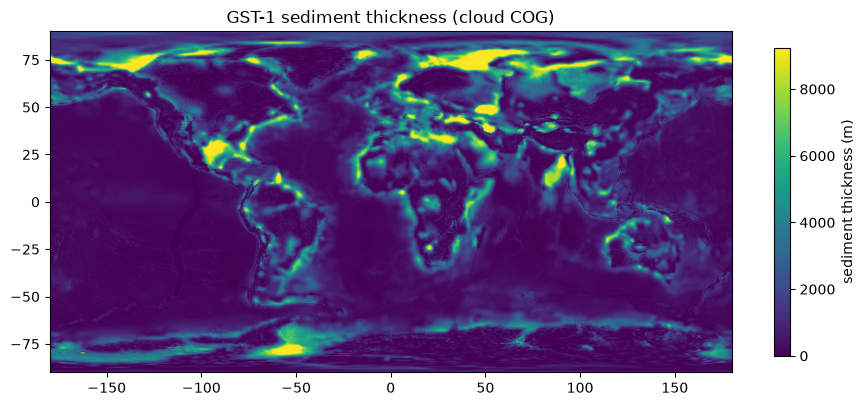

In [6]:
arr = np.ma.masked_equal(cogs["cloud (catalog)"], nodata)
fig, ax = plt.subplots(figsize=(11, 5))
im = ax.imshow(arr, extent=(-180.0625, 180.0625, -90.0625, 90.0625), cmap="viridis", vmin=0, vmax=np.percentile(arr.compressed(), 99))
fig.colorbar(im, label="sediment thickness (m)", shrink=0.8)
ax.set_title("GST-1 sediment thickness (cloud COG)")
plt.show()

## 6) Read a window from the cloud COG

Only the tiles that are needed are downloaded (HTTP range requests). Here the Nile delta region.

In [7]:
from rasterio.windows import from_bounds

with rasterio.open(cloud_href) as src:
    win = from_bounds(29.0, 29.0, 33.0, 32.0, src.transform)
    sub = src.read(1, window=win, masked=True)
print("window shape:", sub.shape, "| min/mean/max (m):", float(sub.min()), float(sub.mean()), float(sub.max()))

window shape: (24, 32) | min/mean/max (m): 1595.199951171875 5848.638671875 9994.7998046875
